### Importing the required Libraries.

In [83]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy.stats import gaussian_kde
import datetime as dt

### Loading the Data Set.


In [84]:
data_path = pd.read_csv('C:/Users/feyis/Desktop/OIBSIP/DataAnalytics-L1-EDARetailSales/retail_sales_dataset.csv', parse_dates=['Date'])
sales = data_path
sales

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100
...,...,...,...,...,...,...,...,...,...
995,996,2023-05-16,CUST996,Male,62,Clothing,1,50,50
996,997,2023-11-17,CUST997,Male,52,Beauty,3,30,90
997,998,2023-10-29,CUST998,Female,23,Beauty,4,25,100
998,999,2023-12-05,CUST999,Female,36,Electronics,3,50,150


### _Examine the first Ten records_

In [85]:
sales.head(10)

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100
5,6,2023-04-25,CUST006,Female,45,Beauty,1,30,30
6,7,2023-03-13,CUST007,Male,46,Clothing,2,25,50
7,8,2023-02-22,CUST008,Male,30,Electronics,4,25,100
8,9,2023-12-13,CUST009,Male,63,Electronics,2,300,600
9,10,2023-10-07,CUST010,Female,52,Clothing,4,50,200


### _Examine the last Ten records_

In [86]:
sales.tail(10)

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
990,991,2023-12-26,CUST991,Female,34,Clothing,2,50,100
991,992,2023-08-21,CUST992,Female,57,Electronics,2,30,60
992,993,2023-02-06,CUST993,Female,48,Electronics,3,50,150
993,994,2023-12-18,CUST994,Female,51,Beauty,2,500,1000
994,995,2023-04-30,CUST995,Female,41,Clothing,1,30,30
995,996,2023-05-16,CUST996,Male,62,Clothing,1,50,50
996,997,2023-11-17,CUST997,Male,52,Beauty,3,30,90
997,998,2023-10-29,CUST998,Female,23,Beauty,4,25,100
998,999,2023-12-05,CUST999,Female,36,Electronics,3,50,150
999,1000,2023-04-12,CUST1000,Male,47,Electronics,4,30,120


### Checked the Data Set Dimensions
_Having 1000 rows and 9 Columns_

In [87]:
sales.shape

(1000, 9)

### Inspecting Column names and Data Types
_Which shows the column names, Data types, number of non-null entries, memory usage_

In [88]:
sales.info

<bound method DataFrame.info of      Transaction ID       Date Customer ID  Gender  Age Product Category  \
0                 1 2023-11-24     CUST001    Male   34           Beauty   
1                 2 2023-02-27     CUST002  Female   26         Clothing   
2                 3 2023-01-13     CUST003    Male   50      Electronics   
3                 4 2023-05-21     CUST004    Male   37         Clothing   
4                 5 2023-05-06     CUST005    Male   30           Beauty   
..              ...        ...         ...     ...  ...              ...   
995             996 2023-05-16     CUST996    Male   62         Clothing   
996             997 2023-11-17     CUST997    Male   52           Beauty   
997             998 2023-10-29     CUST998  Female   23           Beauty   
998             999 2023-12-05     CUST999  Female   36      Electronics   
999            1000 2023-04-12    CUST1000    Male   47      Electronics   

     Quantity  Price per Unit  Total Amount  
0        

### Date has been converted from String format to the date time format

In [89]:
sales.dtypes

Transaction ID               int64
Date                datetime64[us]
Customer ID                    str
Gender                         str
Age                          int64
Product Category               str
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object

### Checking for any missing values.
_This counts for any missing values in each column._
_Initial inspection showed zero missing values_

In [90]:
sales.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

### Checking for any duplicates in the data set.

In [91]:
sales.duplicated().sum()

np.int64(0)

### Checking if the Transaction identifiers are Unique.
_Inspections showed result is "0", which means Unique_

In [92]:
sales.duplicated().sum()

np.int64(0)

### Numerical Analysis and Visualisation

In [93]:
sales.describe()

,Transaction ID,Date,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,2023-07-03 00:25:55.200000,41.39200,2.514000,179.890000,456.000000
min,1.000000,2023-01-01 00:00:00,18.00000,1.000000,25.000000,25.000000
25%,250.750000,2023-04-08 00:00:00,29.00000,1.000000,30.000000,60.000000
50%,500.500000,2023-06-29 12:00:00,42.00000,3.000000,50.000000,135.000000
75%,750.250000,2023-10-04 00:00:00,53.00000,4.000000,300.000000,900.000000
max,1000.000000,2024-01-01 00:00:00,64.00000,4.000000,500.000000,2000.000000
std,288.819436,NaN,13.68143,1.132734,189.681356,559.997632


        
## My Observations: 
### Initial Data Inspection
The retail sales dataset contains 1,000 rows ans 9 columns covering transaction identifiers, dates, customer demographics, product categories, quantities, unit prices, and total transaction amounts.

The initial inspection revealed no missing values or completely duplicated records. However, the Date column was initially stored as an object data type and required conversion to dateTime format to support time - series analysis.

The dataset appears suitable for further exploratory data analysis, subject to additional checks of data consistency and validity. 

### Descriptive Analysis

In [94]:
# Select all the Numerical Columns
numerical_columns = sales.select_dtypes(include='number').columns


In [95]:
# Disply the Numerical columns
print(numerical_columns.tolist())

['Transaction ID', 'Age', 'Quantity', 'Price per Unit', 'Total Amount']


### Calculate the MEAN

In [96]:
# Excluding the Transaction ID because it is an identifier.
sales_columns = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']

# The mean value:
mean_values = sales[sales_columns].mean()
print('MEAN VALUES')
print(mean_values)

MEAN VALUES
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64


### The Mean age of the customers in the Dataset is **41 Years** 
### The Mean Transaction value in the Dataset is **456**

In [97]:
# Excluding the Transaction ID because it is an identifier.
sales_columns = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']

# The mean value:
median_values = sales[sales_columns].median()
print('MEDIAN VALUES')
print(median_values)

MEDIAN VALUES
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64


### Observing that mean transaction amount was at 456 while the Median transaction amount was at 135;
### The Median helps us understand the typical transaction value without allowing unusually large purchases to dominate the result.

#### Calculating the MODE:
_Highest occuring values in the dataset_

In [98]:
# Calculate Mode:
mode_values = sales[sales_columns].mode()
print('The MODE')
print(mode_values)

The MODE
   Age  Quantity  Price per Unit  Total Amount
0   43       4.0            50.0          50.0
1   64       NaN             NaN           NaN


####
_In this dataset, the most common age with frequent number is **Age 43**_
####

### Calculating the Standard deviation

In [99]:
# calculate standard deviation:
std_values = sales[sales_columns].std()
print('STANDARD DEVIATION VALUES:')
print(std_values)

STANDARD DEVIATION VALUES:
Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amount      559.997632
dtype: float64


MEAN VALUES
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000

#### 
**Age** tends to have a lower STD than to the mean value,

**Quantity** tends to have a lower value than the mean value,

**Price per Unit** has a higher value(189.68) than the mean value(179.89),

**Total Amount** has a very high value(559.99) than the mean value(456.00).

#### Combining All Statistics into a Single Table;


In [100]:
# Calculate all four Descriptive statistics
descriptive_stats = sales[sales_columns].agg(['mean', 'median', lambda x: x.mode().iloc[0], 'std'])

# Renaming the rows for readability:
descriptive_stats.index = ['Mean', 'Median', 'Mode', 'Standard Deviation']

# Display the results:
descriptive_stats.round(2)

,Age,Quantity,Price per Unit,Total Amount
Mean,41.39,2.51,179.89,456.0
Median,42.00,3.00,50.00,135.0
Mode,43.00,4.00,50.00,50.0
Standard Deviation,13.68,1.13,189.68,560.0


#### Relationships between Mean and Median:

In [101]:
comparison_rel = pd.DataFrame({'Mean': sales[sales_columns].mean(),
                           'Median': sales[sales_columns].median()})

comparison_rel['Difference'] = (
    comparison_rel['Mean'] - comparison_rel['Median']
)
comparison_rel.round(2)

,Mean,Median,Difference
Age,41.39,42.0,-0.61
Quantity,2.51,3.0,-0.49
Price per Unit,179.89,50.0,129.89
Total Amount,456.00,135.0,321.00


#### Mean of the AGE is less than Median indicates a Left skewed distribution.
#### Mean of the Quantity is less than the median quantity indicates a Left skewed distribution.
#### Both mean of 'Price per Unit, and that of Total Amount' is greater than their Median...This indicates a Right-skewed dsitribution.

### Time Series Analysis:
#### Monthly and Quarterly Slaes Trend.

##### The objective is to identify sales patterns, periods of high and low revnue, 
##### and potential trends that could inform business decisions.

In [102]:
sns.set_theme(style='whitegrid')

In [103]:
# Checcking that the Date column is in the correct date format.
sales['Date'] = pd.to_datetime(sales['Date'])
print(sales['Date'].dtype)

datetime64[us]


In [104]:
# Checking th Date range 
print('First transaction date:', sales['Date'].min())
print('Last transaction date:', sales['Date'].max())

First transaction date: 2023-01-01 00:00:00
Last transaction date: 2024-01-01 00:00:00


In [105]:
# To see the distribution of transaction dates;
sales['Date'].describe()

count                          1000
mean     2023-07-03 00:25:55.200000
min             2023-01-01 00:00:00
25%             2023-04-08 00:00:00
50%             2023-06-29 12:00:00
75%             2023-10-04 00:00:00
max             2024-01-01 00:00:00
Name: Date, dtype: object

In [106]:
# Extract the Month, Quarter and Year:
sales['Year'] = sales['Date'].dt.year
sales['Month'] = sales['Date'].dt.month
sales['Quarter'] = sales['Date'].dt.quarter



In [107]:
sales['Month_Name'] = sales['Date'].dt.month_name()

sales['Year_Month'] = sales['Date'].dt.to_period('M')
print(sales)

     Transaction ID       Date Customer ID  Gender  Age Product Category  \
0                 1 2023-11-24     CUST001    Male   34           Beauty   
1                 2 2023-02-27     CUST002  Female   26         Clothing   
2                 3 2023-01-13     CUST003    Male   50      Electronics   
3                 4 2023-05-21     CUST004    Male   37         Clothing   
4                 5 2023-05-06     CUST005    Male   30           Beauty   
..              ...        ...         ...     ...  ...              ...   
995             996 2023-05-16     CUST996    Male   62         Clothing   
996             997 2023-11-17     CUST997    Male   52           Beauty   
997             998 2023-10-29     CUST998  Female   23           Beauty   
998             999 2023-12-05     CUST999  Female   36      Electronics   
999            1000 2023-04-12    CUST1000    Male   47      Electronics   

     Quantity  Price per Unit  Total Amount  Year  Month  Quarter Month_Name  \
0      

In [108]:
# Monthly Sales Analysis:
# Total Sales by Month:

monthly_sales = (sales.groupby('Year_Month')['Total Amount'].sum()
                 .reset_index()
                 )

monthly_sales.columns = ['Year_Month', 'Total_Sales']

print(monthly_sales)

   Year_Month  Total_Sales
0     2023-01        35450
1     2023-02        44060
2     2023-03        28990
3     2023-04        33870
4     2023-05        53150
5     2023-06        36715
6     2023-07        35465
7     2023-08        36960
8     2023-09        23620
9     2023-10        46580
10    2023-11        34920
11    2023-12        44690
12    2024-01         1530


In [109]:
# Inspecting the Highest And Lowest Months Sales:
highest_sales_month = monthly_sales.loc[monthly_sales['Total_Sales'].idxmax()]


lowest_sales_month = monthly_sales.loc[monthly_sales['Total_Sales'].idxmin()]

print('Month with Highest Sales: ')
print(highest_sales_month)

print("-------------------")
print("-------------------")

print('Month with Lowest Sales: ')
print(lowest_sales_month)


Month with Highest Sales: 
Year_Month     2023-05
Total_Sales      53150
Name: 4, dtype: object
-------------------
-------------------
Month with Lowest Sales: 
Year_Month     2024-01
Total_Sales       1530
Name: 12, dtype: object


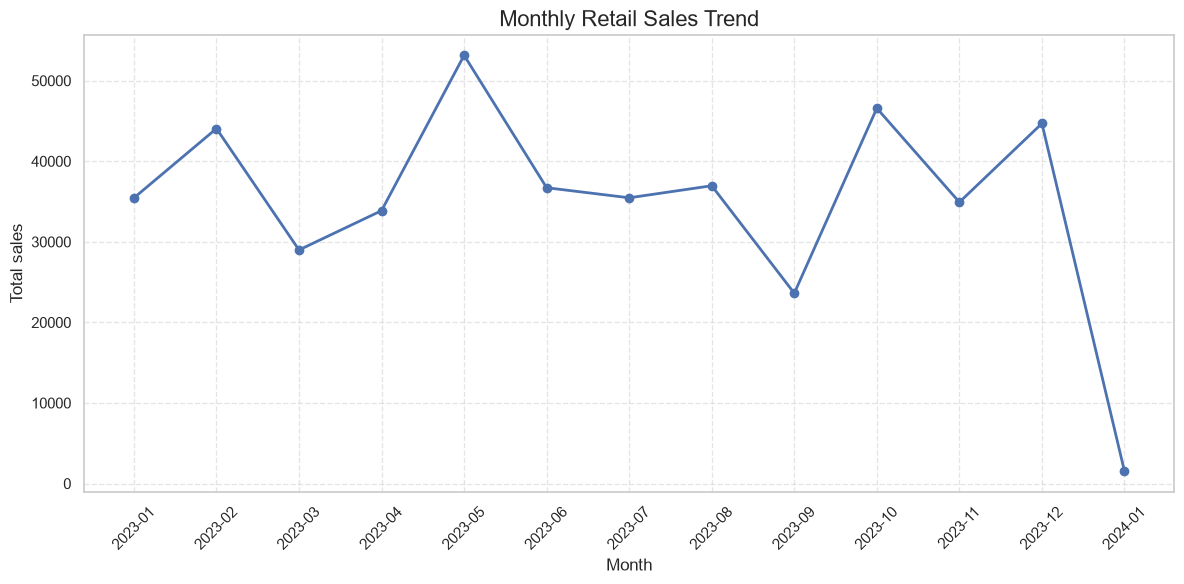

In [110]:
# Visualise Monthly Sales Using line charts:
plt.figure(figsize=(12,6))

plt.plot(
    monthly_sales['Year_Month'].astype(str),
    monthly_sales['Total_Sales'],
    marker='o',
    linewidth=2
)

plt.title('Monthly Retail Sales Trend', fontsize=16)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total sales', fontsize=12)
plt.xticks(rotation=45)

plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.show()


### Observations from the line Chart:
##### Month with the highest sales record was *May, 2023*.
##### Month with the Lowest sales record was *January, 2024*.
##### Sales did not increased passed the previous month highest... **it therefore decreases as seen.**`
##### There was a sharp increase in sales from the month of April to May, 2023; and also in the 
##### month of september to october, 2023. while the momentum could not be maintained in the month of 
##### November, 2023; there was a sharp decline recorded in the month of January, 2024.
##### Sales was seen as to only be slightly  relatively stable through the period's of June, 2023 to August, 2023.


### Quarterly Sales Analysis:

In [111]:
# Calculate Total sales by Quarter

quarterly_sales = (sales.groupby(['Year', 'Quarter'])['Total Amount'].sum().reset_index())

quarterly_sales.columns = ['Year','Quarter', 'Total_Sales']

quarterly_sales['Year_Quarter'] = (quarterly_sales['Year'].astype(str) + 'Q' + quarterly_sales['Quarter'].astype(str))

print(quarterly_sales)


   Year  Quarter  Total_Sales Year_Quarter
0  2023        1       108500       2023Q1
1  2023        2       123735       2023Q2
2  2023        3        96045       2023Q3
3  2023        4       126190       2023Q4
4  2024        1         1530       2024Q1


##### Grouping by both year and Quarter allows for keeping each quarter associated with the correct Year. 
##### It would allow for comparing quarterly performance chronologically.

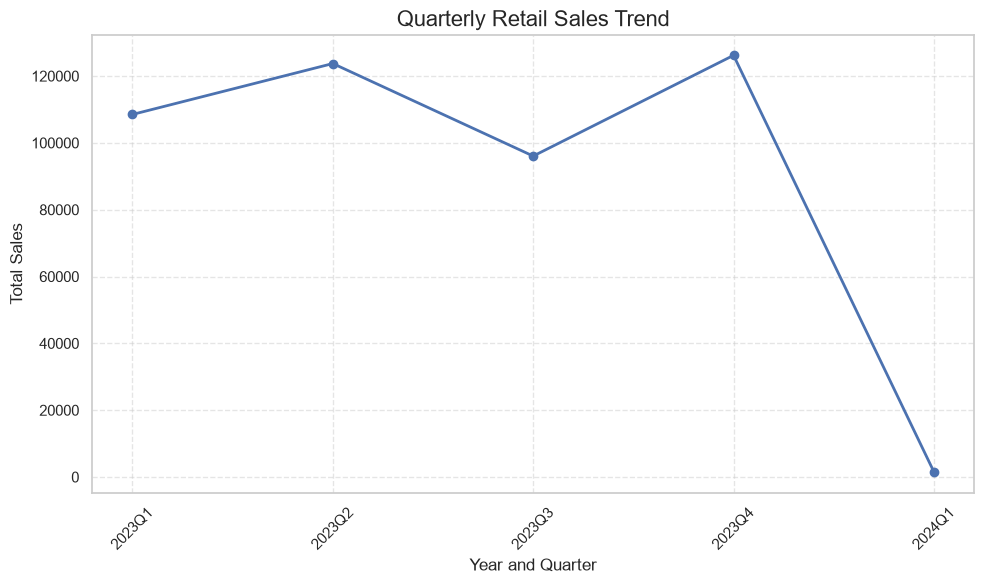

In [112]:
# Visualize Quarterly Sales Using a line Chart.

plt.figure(figsize=(10, 6))

plt.plot(quarterly_sales['Year_Quarter'],
         quarterly_sales['Total_Sales'],
         marker='o',
         linewidth=2
         )

plt.title('Quarterly Retail Sales Trend', fontsize=16)
plt.xlabel('Year and Quarter', fontsize=12)
plt.ylabel('Total Sales', fontsize=12)

plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()

plt.show()

#### Observations from the Quarterly Sales Period:
##### It was observed that Q4 of 2023 has the highest sales record.
##### It was seen that Q1 of 2024 has the Lowest sales record.
##### It was observd that at each quarters, Sales were increasing and also Decreasing.
##### There was substantial differences between each quarters; as there were sharp increase, also was sharp decrease.
##### I can see that the Quarterly pattern somewhat agrees with the monthly chart.
#### Finally, if quarter sales increase across successive periods, this may sugest improving revenue performance.
#### If they decrease, the Business may need to investigate whetger fewer transactions, 
#### lower purchase quantities, or lower transactions values are responsible.

In [113]:
# Compare Monthly Sales Performance:

monthly_sales['Previous_Month_Sales'] = (monthly_sales['Total_Sales'].shift(1))

monthly_sales['Sales_Change'] = (monthly_sales['Total_Sales'] - monthly_sales['Previous_Month_Sales'])

monthly_sales['Percentage_Change'] = (monthly_sales['Sales_Change'] / monthly_sales['Previous_Month_Sales'] * 100)

monthly_sales.round(2)


C:\Users\feyis\AppData\Local\Temp\ipykernel_8424\2238406481.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  monthly_sales.round(2)


,Year_Month,Total_Sales,Previous_Month_Sales,Sales_Change,Percentage_Change
0,2023-01,35450,NaN,NaN,NaN
1,2023-02,44060,35450.0,8610.0,24.29
2,2023-03,28990,44060.0,-15070.0,-34.20
3,2023-04,33870,28990.0,4880.0,16.83
4,2023-05,53150,33870.0,19280.0,56.92
5,2023-06,36715,53150.0,-16435.0,-30.92
6,2023-07,35465,36715.0,-1250.0,-3.40
7,2023-08,36960,35465.0,1495.0,4.22
8,2023-09,23620,36960.0,-13340.0,-36.09
9,2023-10,46580,23620.0,22960.0,97.21


In [114]:
# Identify the Largest Monthly Increase and Decrease:
# We can use the percentage change column to identity the most significant month-month movements.

In [115]:
# First, exclude the first month for which no previous-month comparison exists.

monthly_changes = monthly_sales.dropna(subset=['Sales_Change'].copy())

In [116]:
# Findt the largest Absolute increase:

largest_increase = monthly_changes.loc[monthly_changes['Sales_Change'].idxmax()]

print('Largest increase in Monthly Sales')
print(largest_increase)

print('-----------')
print('-----------')


# Find the Largest Absolute decrease:

lowest_decrease = monthly_changes.loc[monthly_changes['Sales_Change'].idxmin()]

print("Lowest Decrease in Monthly Sales")
print(lowest_sales_month)

print('-----------')
print('-----------')


Largest increase in Monthly Sales
Year_Month                2023-10
Total_Sales                 46580
Previous_Month_Sales      23620.0
Sales_Change              22960.0
Percentage_Change       97.205758
Name: 9, dtype: object
-----------
-----------
Lowest Decrease in Monthly Sales
Year_Month     2024-01
Total_Sales       1530
Name: 12, dtype: object
-----------
-----------


#### These calculations identify the largest increase and decrease in the
 *monetary amount of sales*, not necessarily the largest percentage changes.

#### Observations From the Monthly Sales Trend:
##### Highest performing Month = **_The month of October, 2023._**
##### Lowest performing Month = **_ The Month of January, 2024._**
##### Overall pattern = **_Sales was fluntuacting generally throughout the Calendar Year, some visible highs, and some lows_**
##### Notable Changes = In each consecutive months, these changes were observed; _**Sales was seen plummeting around the month of September through October, while a very declined in sales seen in January, 2024.**_

#### CUSTOMER DEMOGRAPHIC ANALYSIS

In [117]:
# Examine the Age column
# Display the first Ten customers:
sales['Age'].head(10)

0    34
1    26
2    50
3    37
4    30
5    45
6    46
7    30
8    63
9    52
Name: Age, dtype: int64

In [118]:
# Examine the min, max, and Average customer Age:
# Summary Statistics for customer Age.
print('Mininum Age: ', sales['Age'].min())
print('Maxinum Age: ', sales['Age'].max())
print('Mean Age: ', sales['Age'].mean())
print('Median Age: ', sales['Age'].median())

Mininum Age:  18
Maxinum Age:  64
Mean Age:  41.392
Median Age:  42.0


In [119]:
sales['Age'].describe()

count    1000.00000
mean       41.39200
std        13.68143
min        18.00000
25%        29.00000
50%        42.00000
75%        53.00000
max        64.00000
Name: Age, dtype: float64

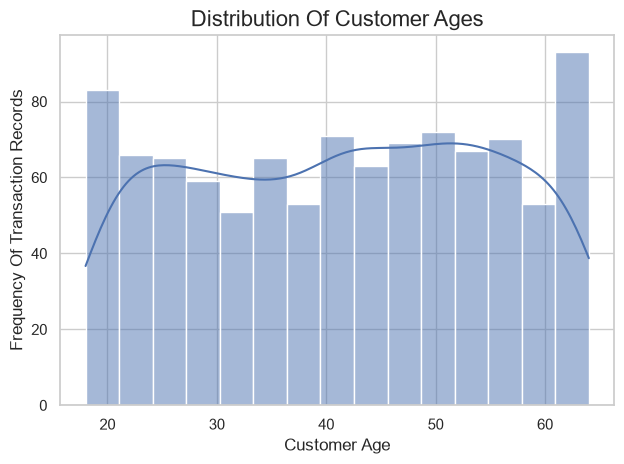

In [120]:
# visualising the Age Distribution Using A Histogram:
sns.set_theme(style='whitegrid')
plt.Figure(figsize=(10,6))

sns.histplot(
    data=sales,
    x='Age',
    bins=15,
    kde=True
)

plt.title('Distribution Of Customer Ages', fontsize=16)
plt.xlabel('Customer Age', fontsize=12)
plt.ylabel('Frequency Of Transaction Records', fontsize=12)
plt.tight_layout()

plt.show()

##### From the Histogram chart, the distribution was greatly concentrated around the Ages of 60 and Above in recorded transactions.
##### However, theis does not implied that people in these age groups represent the largest number of unique customers.
 ##### Repeat purchases could influence the distribution.

GROUPING CUSTOMERS' INTO AGE CATEGORIES:

In [121]:
# Sampled Age groups for this project using these categories analytically;
# Young Adults = 18 -29
# Adults = 30 - 44
# Middle aged adults = 45 - 59
# Older Adults = 60 and Above.


In [122]:
# Check for Ages Below 18 in the Dataset:

print('Customers Younger than 18: ', (sales['Age'] < 18).sum())

# Results was Zero customers below the Age 18.

Customers Younger than 18:  0


In [123]:
# Age Groups:
age_bins = [0, 17, 29, 44, 59, float('inf')]

age_labels = ['Under 18',
              'Young Adults (18 - 29)', 
              'Adults (30 - 44)', 
              'Middle-Aged Adults (45 - 59)',
              'Older Adults (60+)'
              ]


sales['Age Group'] = pd.cut(sales['Age'],
                          bins=age_bins,
                          labels=age_labels,
                          include_lowest=True
                          )



##### CALCULATE THE DISTRIBUTION OF AGE GROUPS:

In [124]:
age_group_counts = (
    sales['Age Group'].value_counts(sort=False)
)

print(age_group_counts)

Age Group
Under 18                          0
Young Adults (18 - 29)          251
Adults (30 - 44)                308
Middle-Aged Adults (45 - 59)    326
Older Adults (60+)              115
Name: count, dtype: int64


In [125]:
# Calculate the Percentage Distribution
age_group_percentages = (
    sales['Age'].value_counts(normalize=True, sort=False) * 100
)

print('Age Group Percentage: ', age_group_percentages.round(2))

Age Group Percentage:  Age
34    2.8
26    2.2
50    2.3
37    1.6
30    2.2
45    1.7
46    2.5
63    1.7
52    2.2
23    2.4
35    2.2
22    2.7
64    3.1
42    2.6
19    2.1
27    2.3
47    2.6
62    2.7
18    2.1
49    1.9
28    2.1
38    1.9
43    3.1
39    1.8
44    1.5
51    3.0
58    1.4
48    1.8
55    2.1
20    2.1
40    2.4
54    2.8
36    1.5
31    2.2
21    2.0
57    3.0
25    2.0
56    1.9
29    1.6
61    1.8
32    1.9
41    2.1
59    1.7
60    2.2
33    1.0
53    1.7
24    1.5
Name: proportion, dtype: float64


In [126]:
# Combining the Counts and Percentage into a Table:
# NB: This table helps to identify which group accounts for the largest share of the transaction records.


age_group_summary = pd.DataFrame({
    'Transaction Records': age_group_counts,
    'Percentage (%)': age_group_percentages
})

age_group_summary

,Transaction Records,Percentage (%)
18,NaN,2.1
19,NaN,2.1
20,NaN,2.1
21,NaN,2.0
22,NaN,2.7
23,NaN,2.4
24,NaN,1.5
25,NaN,2.0
26,NaN,2.2
27,NaN,2.3


##### VISUALISE THE AGE GROUP DISTRIBUTION

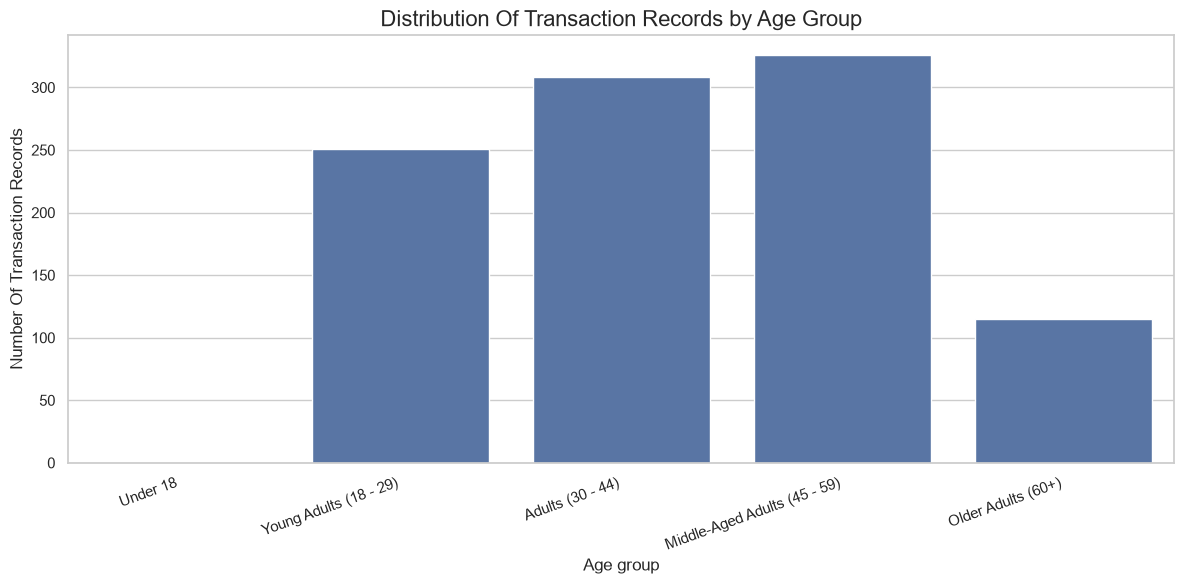

In [127]:
# using a BarChart comparing sizes of discrete categories.

plt.figure(figsize=(12, 6))

sns.countplot(
    data= sales,
    x='Age Group',
    order=age_labels
)

plt.title('Distribution Of Transaction Records by Age Group', fontsize= 16)
plt.xlabel('Age group', fontsize= 12)
plt.ylabel('Number Of Transaction Records', fontsize= 12)

plt.xticks(rotation = 20, ha='right')

plt.tight_layout()
plt.show()

OBSERVATIONS FROM THE BARCHART
###### The Age Group with the Highest Frequency = **Middle Aged Adults (45 - 59)**
###### The Age Group with the Highest Frequency = **Older Adults (60+)**
###### The Distribution is more concentrated in the Older groups than of the Younger group.
###### The Disbribution is not seen to be evenly balanced across the groups.

GENDER DISTRIBUTION ANALYSIS

In [128]:
# Examining the Gender Column for nummber of transactions record, associated with each Gender category.

sales['Gender'].value_counts(dropna=False)

Gender
Female    510
Male      490
Name: count, dtype: int64

In [129]:
# Calculate the Percentages of Gender Distributions.
gender_percentages = (sales['Gender'].value_counts(normalize=True) * 100)

print('GENDER DISTRIBUTION % :',gender_percentages.round(2))

GENDER DISTRIBUTION % : Gender
Female    51.0
Male      49.0
Name: proportion, dtype: float64


##### From the Gender Distribution Percentage Data, it,s observed that:
##### Female has 51% of the total Distribution,
##### Male has 49% of the total Distribution,

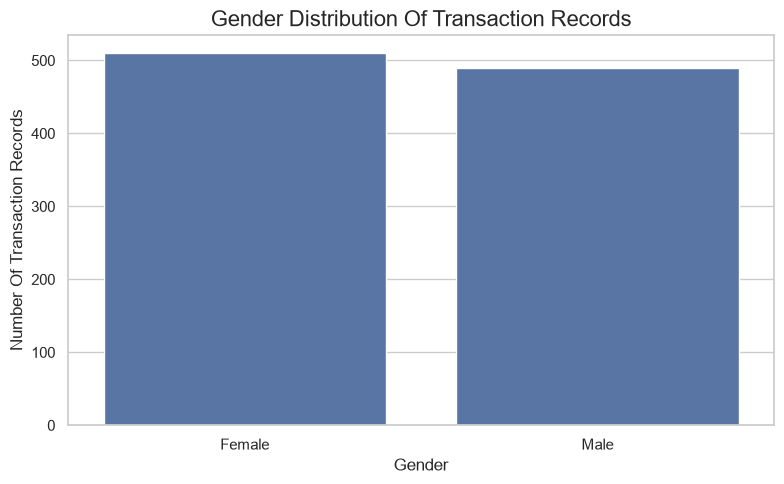

In [130]:
# Using a BArChart to display the Number of Transaction Records Associated with each Gender CAtegory.

plt.figure(figsize=(8, 5))
sns.countplot(
    data=sales,
    x='Gender',
    order=sales['Gender'].value_counts().index
)

plt.title('Gender Distribution Of Transaction Records', fontsize=16)
plt.xlabel('Gender', fontsize=12)
plt.ylabel('Number Of Transaction Records', fontsize=12)

plt.tight_layout()
plt.show()

##### The BarChart reveals that the Female Gender category has the greater share of the recorded transactions.

DISTINGUISH UNIQUE CUSTOMERS FROM TRANSACTIONS

In [131]:
# Using the Customer Id column

total_transactions = len(sales)

unique_customers = sales['Customer ID'].unique()

print('Total Transaction Records: ', total_transactions)

print('**************************************************')
print('**************************************************')

print('Unique Customers: ', unique_customers)

print('----------------------------------------------')
print('----------------------------------------------')

Total Transaction Records:  1000
**************************************************
**************************************************
Unique Customers:  <StringArray>
[ 'CUST001',  'CUST002',  'CUST003',  'CUST004',  'CUST005',  'CUST006',
  'CUST007',  'CUST008',  'CUST009',  'CUST010',
 ...
  'CUST991',  'CUST992',  'CUST993',  'CUST994',  'CUST995',  'CUST996',
  'CUST997',  'CUST998',  'CUST999', 'CUST1000']
Length: 1000, dtype: str
----------------------------------------------
----------------------------------------------


AS OBSERVED THAT THE NUMBER OF TOTAL TRANSACTIONS _(1000)_ EQUALS TO THE TOTAL NUMBER OF UNIQUE CUSTOMERS _(1000)_ DURING THE RECORDED PERIOD.

##### CALCULATE THE AVERAGE NUMBER OF TRANSACTIONS PER CUSTOMER

In [132]:
# SIMPLE measure Of Overall Transaction Frequency

total_transactions = 1000

unique_customers = 1000

average_transactions_per_customer = (total_transactions) / (unique_customers)

print('Average Transactions Per Customer: ', round(average_transactions_per_customer, 2))

Average Transactions Per Customer:  1.0


DEMOGRAPHICS AMONG UNIQUE CUSTOMERS


In [133]:
# Record of transactions among Each Customers
customers = (
    sales[['Customer ID', 'Age', 'Gender']].drop_duplicates(subset='Customer ID').copy()
)



In [134]:
# Check That Each Customer Appears Once:
print('Unique Customer Records: ', len(customers))

print('Unique Customer ID: ', customers['Customer ID'].nunique())

Unique Customer Records:  1000
Unique Customer ID:  1000


_Seeing that the Above Results for Each Customers Record and ID agrees as the Same_, 
_justifies that each customer has consistent record._

In [135]:
# Checking for Whether Customers have inconsistent Demographic information across Transactions.

age_variation = (
    sales.groupby('Customer ID')['Age'].nunique()
)

gender_variation = (
    sales.groupby('Customer ID')['Gender'].nunique()
)

print('Customers With Multiple Recorded Ages: ', (age_variation > 1).sum())
print('-------------------------------------------------------------------------')

print('Customers With Multiple Recorded Gender Category: ', (gender_variation > 1).sum())

Customers With Multiple Recorded Ages:  0
-------------------------------------------------------------------------
Customers With Multiple Recorded Gender Category:  0


These counts as Zero as Each Customer has consistent rcorded age and Gender values.

##### Analyze Unique Customers by Age Groups


In [136]:
customers['Age Group'] = pd.cut(
    customers['Age'],
    bins=age_bins,
    labels= age_labels,
    include_lowest= True
)

unique_customers_age_distribution = (
    customers['Age Group'].value_counts(sort=False)
)

unique_customers_age_percentages = (
    customers['Age Group'].value_counts(normalize=True, sort=False) * 100
)

unique_customers_age_summary = pd.DataFrame({
    'Unique Customers': unique_customers_age_distribution, 
    'Percentage (%)': unique_customers_age_percentages
})

unique_customers_age_summary.round(2) 

# This should give me a more direct view of the Age Distribution among Unique Customers rather than transaction Records.


,Unique Customers,Percentage (%)
Age Group,,
Under 18,0,0.0
Young Adults (18 - 29),251,25.1
Adults (30 - 44),308,30.8
Middle-Aged Adults (45 - 59),326,32.6
Older Adults (60+),115,11.5


### PRODUCT ANALYSIS

In [137]:
# Display Product category
print(sales['Product Category'].unique())

<StringArray>
['Beauty', 'Clothing', 'Electronics']
Length: 3, dtype: str


In [138]:
# Count Number of Transactions within Each Categories.
category_counts = sales['Product Category'].value_counts()

print(category_counts)

Product Category
Clothing       351
Electronics    342
Beauty         307
Name: count, dtype: int64


#### What Are we Investigating?
##### How many product categories exist?
##### Which category appears most frequently?
##### Which category appears least frequently?
##### How are transaction records distributed across categories?



In [139]:
# Calculate Total Quantity sold by Product Category

category_quantity = (sales.groupby('Product Category')['Quantity'].sum().reset_index())

# Rename Columns

category_quantity.columns = ['Product Category', 'Total Quantity Sold']

# Sort from Highest To Lowest

category_quantity = category_quantity.sort_values(by='Total Quantity Sold', ascending=False)

print(category_quantity)

  Product Category  Total Quantity Sold
1         Clothing                  894
2      Electronics                  849
0           Beauty                  771


### INTERPRETATION

The Category with the highest total quantity sold represents the category with the greatest recorded unit sales..
This gives us an indication of product Demand across the available categories.

#### BUSINESS RELEVANCE

Retailers can use this information when planning inventory replenishment and identifying categories with stronger purchasing activity.

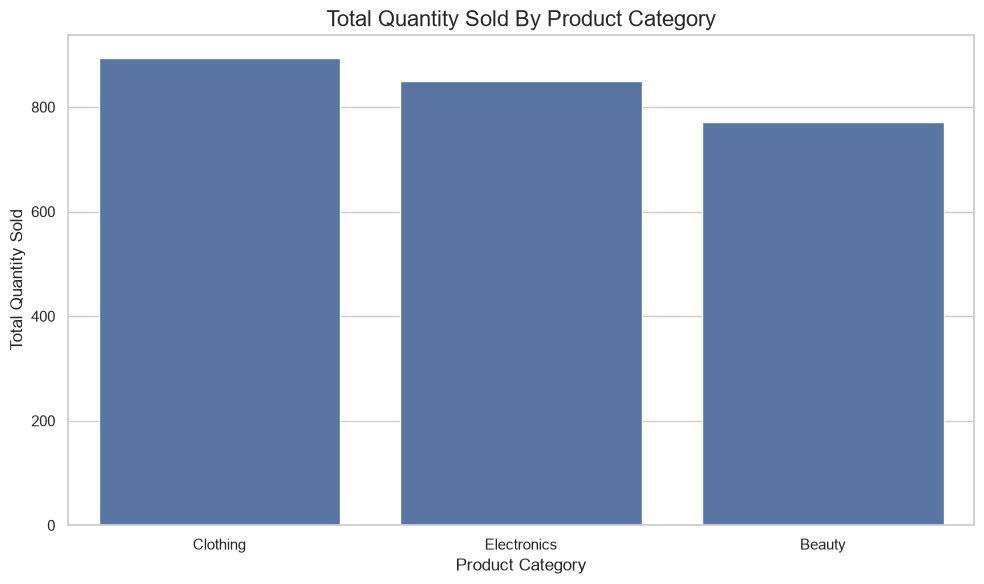

In [140]:
# Visualise Quantity Sold with Product Category ( Using a BarChart).

plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_quantity,
    x='Product Category',
    y='Total Quantity Sold'
)

plt.title('Total Quantity Sold By Product Category', fontsize=16)

plt.xlabel('Product Category', fontsize=12)

plt.ylabel('Total Quantity Sold', fontsize=12)

plt.tight_layout()

plt.show()

#### OBSERVATIONS:
##### Category with highest sales Volume? = _**Clothing**_
##### Category with Lowest Sales Volume? = _**Beauty**_
##### Are differences between Categories substantial? = **YES**
##### Are Sales Volumes relatively Balanced? = _**Sales Volumes varies across each Categories**_

### REVENUE ANALYSIS BY PRODUCT CATEGORY:

In [141]:
# CAlculate Revenue by Product Category

category_revenue = (sales.groupby('Product Category')['Total Amount'].sum().reset_index())

# Revenue Columns

category_revenue.columns = ['Product Category', 'Total Revenue']

# Sort Categories By Revenue

category_revenue = category_revenue.sort_values(by='Total Revenue', ascending=False)

print(category_revenue)

  Product Category  Total Revenue
2      Electronics         156905
1         Clothing         155580
0           Beauty         143515


### Explanation:
#### This calculation adds together the transaction amounts associated with each product category.
#### A Category with High Sales Volumes may not necessarily means it generates the highest revenue.

#### **VISUALISE REVENUE BY PRODUCT CATEGORY**

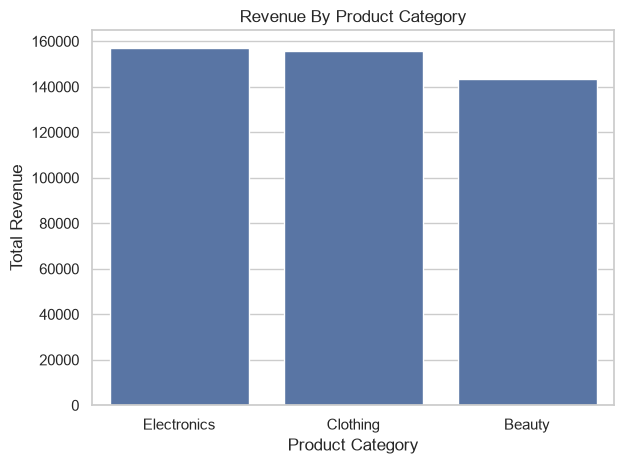

In [142]:
plt.Figure(figsize=(10, 6))

sns.barplot(
    data=category_revenue,
    x='Product Category',
    y='Total Revenue'
)

plt.title('Revenue By Product Category')
plt.xlabel('Product Category', fontsize=12)
plt.ylabel('Total Revenue', fontsize=12)
plt.tight_layout()
plt.show()

#### INTERPRETATION:
_Taller Bars represent categories generating higher Revenue._
_Shorter Bars represent categories generating lower Revenues._

#### **CALCULATE REVENUE CONTRIBUTION** 

In [143]:
# Calculate Total Revenue Across All Category

overall_revenue = sales['Total Amount'].sum()

# Percentage Contributions across Each Categories

category_revenue['Revenue Contribution (%)'] = (
    category_revenue['Total Revenue'] / overall_revenue
) * 100

print(category_revenue.round(2))

  Product Category  Total Revenue  Revenue Contribution (%)
2      Electronics         156905                     34.41
1         Clothing         155580                     34.12
0           Beauty         143515                     31.47


From the Percentage contributions above, **Electronics category** has the largest share of sales. it is important to note incase we want to focus more on inventory and marketing decisions.

#### **COMPARE SALES VOLUME AND REVENUE**

In [144]:
# Merge Quantity and Revenue Summaries

category_performance = pd.merge(
    category_quantity,
    category_revenue,
    on='Product Category'
)

# Display Combined Results

print(category_performance.round(2))

  Product Category  Total Quantity Sold  Total Revenue  \
0         Clothing                  894         155580   
1      Electronics                  849         156905   
2           Beauty                  771         143515   

   Revenue Contribution (%)  
0                     34.12  
1                     34.41  
2                     31.47  


This Table allows us to compare Sales Volume against Revenue.

In [145]:
# Calculate Average Revenue per Unit

category_performance['Average Revenue per Unit'] = (
    category_performance['Total Revenue'] / category_performance['Total Quantity Sold']
)

print(category_performance.round(2))

#NB: This is a weighted average based on units sold, not the simple average of individual transaction prices.

  Product Category  Total Quantity Sold  Total Revenue  \
0         Clothing                  894         155580   
1      Electronics                  849         156905   
2           Beauty                  771         143515   

   Revenue Contribution (%)  Average Revenue per Unit  
0                     34.12                    174.03  
1                     34.41                    184.81  
2                     31.47                    186.14  


### IDENTIFY THE TOP BEST PERFORMING CATEGORY

In [146]:
# Top Three Category by Revenue:

top_categories = category_performance.head(3)

print('Top 3 Product Categories by Revenue: ')
print('---------------------------------------')
print('---------------------------------------')

print(top_categories[
    [
        'Product Category',
        'Total Revenue',
        'Revenue Contribution (%)'
    ]
])

Top 3 Product Categories by Revenue: 
---------------------------------------
---------------------------------------
  Product Category  Total Revenue  Revenue Contribution (%)
0         Clothing         155580                 34.118421
1      Electronics         156905                 34.408991
2           Beauty         143515                 31.472588


#### **Observations:**

##### Category generating highest revenue = _Electronics_
##### Category ranking second = _Clothing_
##### Category ranking third = _Beauty_

#### **COMBINED CONTRIBUTION OF ALL CATEGORIES TO REVENUE**
This helps determine how much of the retailer's total revenue is concentrated in its three leading categories.

In [147]:

top_3_contribution = (
    top_categories['Revenue Contribution (%)'].sum()
)

print('Combined revenue contribution of top 3 categories: ', round(top_3_contribution))

Combined revenue contribution of top 3 categories:  100


### **Business Insights**
##### The comparison between quantity sold and reveue generated provides insight  into the relative financial contribution of each product category.
##### Categories generating high revenue may warrant greater attetion in inventory management and marketing planning. However,
##### Revenue alone does not establish profitability because product costs and operating expenses are not included in the Dataset.

#### It should be Noted however that, this DataSet does not contain an individual _Product Name_ or _Product ID_ column.
#### This means we cannot identify the Top Ten individual Products.
#### What I would do is identify the Best-Performing product Categories and rank them according to quantity sold and revenue generated.

### **CORRELATION ANALYSIS AND HEATMAP**

In [148]:
# Identify Numerical Columns

numerical_columns = sales.select_dtypes(include=['int64', 'float64']).columns

print(numerical_columns.tolist())

['Transaction ID', 'Age', 'Quantity', 'Price per Unit', 'Total Amount']


In [149]:
# We would Exclude Transaction ID from our numerical column because 
# it's simply an identifier which does not represent a measureable business variable.

correlation_columns = [
    'Age',
    'Quantity',
    'Price per Unit',
    'Total Amount'
]

correlation_data = sales[correlation_columns]

print(correlation_data.head())

   Age  Quantity  Price per Unit  Total Amount
0   34         3              50           150
1   26         2             500          1000
2   50         1              30            30
3   37         1             500           500
4   30         2              50           100


### **CALCULATE THE PEARSON CORRELATION MATRIX**

In [150]:
# Calculate Pearson correlation Matrix
correlation_matrix = correlation_data.corr(method='pearson')

print(correlation_matrix)

                     Age  Quantity  Price per Unit  Total Amount
Age             1.000000 -0.023737       -0.038423     -0.060568
Quantity       -0.023737  1.000000        0.017501      0.373707
Price per Unit -0.038423  0.017501        1.000000      0.851925
Total Amount   -0.060568  0.373707        0.851925      1.000000


### **VISUALISE THE CORRELATION MATRIX**

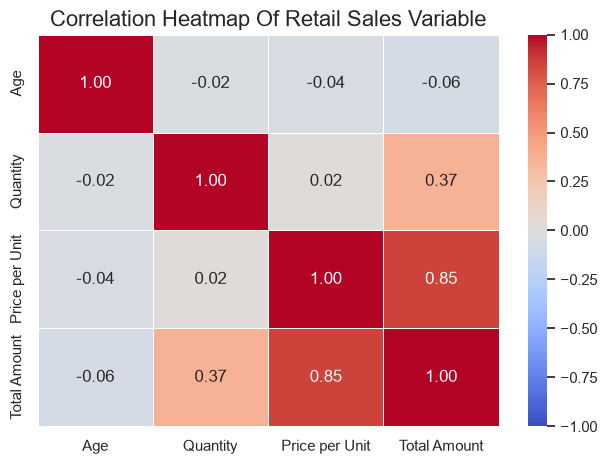

In [151]:
plt.Figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=+1
)

plt.title('Correlation Heatmap Of Retail Sales Variable', fontsize=16)

plt.tight_layout()
plt.show()

In [152]:
# Relationship Between Quantity and Total Amount:

quantity_amount_correlation = sales[
    ['Quantity', 'Total Amount']
    ].corr()

print(quantity_amount_correlation)

              Quantity  Total Amount
Quantity      1.000000      0.373707
Total Amount  0.373707      1.000000


### OBSERVATIONS FROM THE CORRELATIONS:

It was observed that between QUANTITY and TOTAL AMOUNT, there was a moderate positive correlation; higher quantities tend to correspond to higher transaction amounts.


### **CORRELATION BETWEEN AGE AND SPENDING**

In [153]:
age_spending_correlation = sales[['Age', 'Total Amount']].corr()

print(age_spending_correlation)

                   Age  Total Amount
Age           1.000000     -0.060568
Total Amount -0.060568      1.000000


### Obeservation:
This showed a very weak negative correlation.
Which suggests that older customers tend to have lower transaction amounts.

### **CORRELATION BETWEEN UNIT PRICE AND QUANTITY PURCHASE:**

In [154]:
price_quantity_correlation = sales[[
    'Price per Unit', 'Quantity'
]].corr()

print(price_quantity_correlation)

                Price per Unit  Quantity
Price per Unit        1.000000  0.017501
Quantity              0.017501  1.000000


**INTERPRETATION**
##### This showed essentially no linear relationship.
##### A positive correlation could suggest that higher-priced items are associated with larger purchase quantities.
##### However, this dataset does not contain individual product identifiers, so we cannot establish whether the relationship reflects customer price sensitivity or differences between product categories.

### An Additional Visualisation:
Using a scatterplot

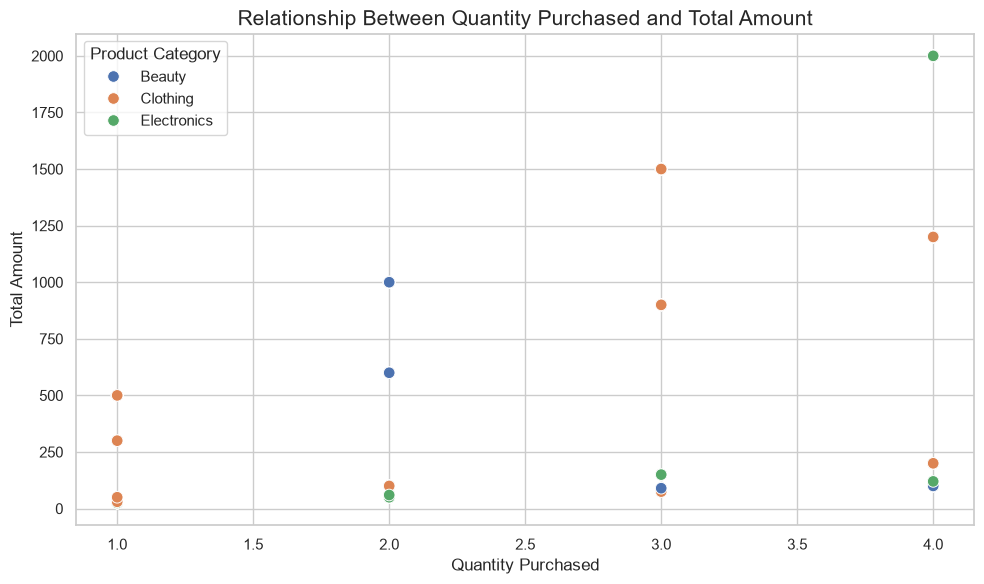

In [155]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sales,
    x='Quantity',
    y='Total Amount',
    hue='Product Category',
    s=70
)

plt.title('Relationship Between Quantity Purchased and Total Amount', fontsize=15)

plt.xlabel('Quantity Purchased', fontsize=12)
plt.ylabel('Total Amount', fontsize=12)
plt.legend(title='Product Category')
plt.tight_layout()
plt.show()


### **Do larger quantities generally correspond to higher transaction amounts?**
##### _Yes, on average. Mean transaction amounts rise from $177 for quantity 1 to $707 for quantity 4. The relationship is positive but not exact: Pearson correlation is 0.37 (Spearman: 0.47). Different unit prices affect the total._

### **Are there noticeable differences between product categories?**
##### _Not large differences in average transaction amount: Beauty $467, Electronics $459, and Clothing $443. Electronics has a somewhat higher median ($150, versus $120 for Beauty and Clothing)._

### **Are there unusually high transaction amounts?**
##### _The maximum is $2,000; it is high compared with the median of $135. However, using the standard 1.5×IQR rule, there are no statistical outliers: the upper threshold is $2,160._

### **Do transactions with the same quantity have different total amounts?**
##### _Yes. Each quantity (1–4) has five distinct totals, reflecting different unit prices. For example, quantity 4 transactions range from $100 to $2,000._

##### _Overall, quantity tends to raise the amount, but unit price is also an important factor_

The strongest relationship is between Quantity and Total Amount. Age has little association with either quantity or total amount, and quantity is not meaningfully associated with unit price. These are associations, not evidence that one variable causes another.

The Age–Total Amount correlation is weak and was not statistically significant at the 5% level (p ≈ 0.056); the Quantity–Total Amount relationship was statistically significant (p < 0.001).

### Business Implications:

_Understanding the relationships betwen purchasing quantity, unit price, and transaction amount can help retailers evaluate purchasing patterns and revenue drivers._

### Limitations:

_Correlation does not establish causation._
_Furthermore, the analysis measures linear relationships and may not identify nonlinear patterns. Repeated customer transactions may also influence the observed relationships._

## **An Additional Visualisation and Business Insight:**


In [156]:
# Reviewing Customer Spending behavior by Age Group and Gender:
# Using a Heatmap to compare average transaction amounts across different age groups and gender categories.

sales[['Age', 'Age Group', 'Gender', 'Total Amount']].head()


,Age,Age Group,Gender,Total Amount
0,34,Adults (30 - 44),Male,150
1,26,Young Adults (18 - 29),Female,1000
2,50,Middle-Aged Adults (45 - 59),Male,30
3,37,Adults (30 - 44),Male,500
4,30,Adults (30 - 44),Male,100


In [157]:
# Calculate Average Transaction Amount by Age Group and Gender:
demographic_spending = (sales.groupby(['Age Group', 'Gender'], observed=False)['Total Amount'].mean().reset_index()
)

demographic_spending.columns = ['Age Group', 'Gender', 'Average Transaction Amount']

print(demographic_spending)

                      Age Group  Gender  Average Transaction Amount
0                      Under 18  Female                         NaN
1                      Under 18    Male                         NaN
2        Young Adults (18 - 29)  Female                  492.441860
3        Young Adults (18 - 29)    Male                  488.770492
4              Adults (30 - 44)  Female                  491.783439
5              Adults (30 - 44)    Male                  451.721854
6  Middle-Aged Adults (45 - 59)  Female                  420.207101
7  Middle-Aged Adults (45 - 59)    Male                  456.019108
8            Older Adults (60+)  Female                  383.454545
9            Older Adults (60+)    Male                  395.416667


In [158]:
# Number of transactions contributing to each Average:

transaction_counts = (sales.groupby(['Age Group', 'Gender'], 
                                    observed=False)['Total Amount']
                                    .count()
                                    .reset_index(name='Transaction Count')
                    )

print(transaction_counts)

                      Age Group  Gender  Transaction Count
0                      Under 18  Female                  0
1                      Under 18    Male                  0
2        Young Adults (18 - 29)  Female                129
3        Young Adults (18 - 29)    Male                122
4              Adults (30 - 44)  Female                157
5              Adults (30 - 44)    Male                151
6  Middle-Aged Adults (45 - 59)  Female                169
7  Middle-Aged Adults (45 - 59)    Male                157
8            Older Adults (60+)  Female                 55
9            Older Adults (60+)    Male                 60


In [159]:
# Visualize Average Transaction Amount by Age Group and Gender Using a Heatmap:

spending_pivot = demographic_spending.pivot(index='Age Group', columns='Gender', values='Average Transaction Amount')

print(spending_pivot)

Gender                            Female        Male
Age Group                                           
Under 18                             NaN         NaN
Young Adults (18 - 29)        492.441860  488.770492
Adults (30 - 44)              491.783439  451.721854
Middle-Aged Adults (45 - 59)  420.207101  456.019108
Older Adults (60+)            383.454545  395.416667


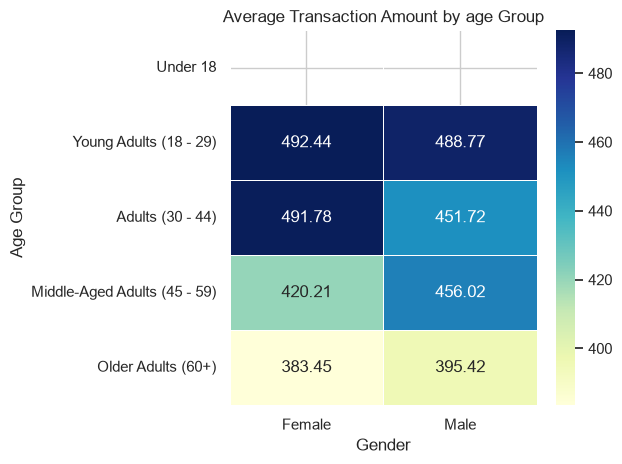

In [160]:
plt.Figure(figsize=(10, 6))
sns.heatmap(
    spending_pivot,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    linewidths=0.5
)

plt.title('Average Transaction Amount by age Group')
plt.xlabel('Gender')
plt.ylabel('Age Group')
plt.tight_layout()
plt.show()


### Observations: Additional Business Insight: Spending Behaviour by Age and Gender
The heatmap illustrates the differences in average transaction amounts across customer age groups and gender.
- The age group with the highest average transaction amount was **Female Young Adults (18 - 29) with (492.44)**
- The age group with the lowest average transaction amount was **Female Older Adults (60+) with (383.45)**
- The gender with the higher average transaction amount in age group **Adults (30 - 44)** was **Female** 
- The result suggests that spending behaviour may vary across demographic groups.

Business Implications:
- The business could use this findings to investigate whether different custome groups respond 
to different product offerings or promotional strategies. However, these patterns shoud be validated with more customer and transaction
data before making major marketing decisions.

## **Conclusion**

This Exploratory Data Analysis examined a retail sales dataset containing 1,000 transaction records and nine variables. The analysis focused on understanding sales performance, customer demographics, product category performance and relationships among numerical variables.

The descriptive statistical analysis provided an overview of customer ages, transaction quantities, unit prices and total transaction amounts.

The time series analysis revealed variations in monthly and quarterly sales performance, helping to identify periods of relatively stronger and weaker sales activity.

Customer demographic analysis examined the distribution of transactions across age groups and gender. The product category analysis identified the categories contributing the highest sales quantities and revenue.

The correlation analysis provided insights into relationships among numerical variables, while the additional demographic spending visualization helped examine differences in average transaction amounts across age groups and gender.

Overall, the analysis demonstrates how exploratory data analysis can support evidence-based retail business decisions by identifying sales patterns, customer behaviour and product category performance.


### **Business Recommendations**

Based on the findings, the following recommendations are proposed:

- **Plan Promotions around Sales Trends:**
_Introduce targeted discounts, seasonal campaigns or loyalty incentives 
during weaker sales periods, while preparing sufficient inventory ahead of stronger periods._

- **Focus on Revenue - generating Categories:**
_Review pricing, product availability and promotional investment across categories. 
Avoid assuming that the highest-revenue category is automatically the most profitable, 
since the dataset does not contain cost information._

- **Improve Inventory Management:**
_Maintain adequate stock levels, monitor replenishment frequency and 
reduce the risk of stockouts in high-demand categories._

- **Customer retention:** 
Investigate repeat purchasing behaviour and consider 
loyalty programmes to encourage customers to make more frequent purchases.


